# Engineering Within Five Original Fields

This notebook reviews the fixed-field compact WoE experiment using packaged aggregate results. All six recipes and controls were evaluated on the established temporal samples. The two-replacement recipe was selected in 2012. On 84,175 labelled 2015 Q1 loans with 2014 term offsets, its log loss was 0.466453 and AUC was 0.6452. The original WoE model remains the primary specification.

The underlying research implementation is in ../research/five_field_engineered_woe_20261122/engineer_five_woe.py. Rebuilding the experiment requires the local loan extract and preparation stages. This notebook runs from the included aggregates.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

repo = Path.cwd()
if not (repo / "project_paths.py").exists():
    repo = repo.parent
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

folder = repo / "research/five_field_engineered_woe_20261122"
model = json.loads((folder / "engineered_woe_spec.json").read_text())
pd.DataFrame(model["transformations"].items(), columns=["Component", "Definition"])

Component,Definition
debt_adjusted_income,annual_inc * (1 - dti / 100)
combined_burden,dti * revol_util / 100
revol_util,Reported revolving utilisation percentage
purpose,Semantic purpose group
inq_last_6mths,Recorded enquiries in the preceding six months


## Readable feature engineering

The example below uses the package's fabricated application records. DTI and utilisation enter as percentage points. The income proxy uses reported gross income and a DTI definition that excludes mortgage and requested-loan payments.

In [2]:
examples = pd.read_csv(repo / "data/synthetic_applications.csv")
engineered = examples[["annual_inc", "dti", "revol_util"]].copy()
for field in engineered:
    engineered[field] = pd.to_numeric(engineered[field].astype(str).str.rstrip("%"))
engineered["debt_adjusted_income"] = engineered.annual_inc * (1 - engineered.dti / 100)
engineered["combined_burden"] = engineered.dti * engineered.revol_util / 100
engineered

annual_inc,dti,revol_util,debt_adjusted_income,combined_burden
68000,17.44,50,56140.8,8.72
68000,17.44,50,56140.8,8.72


## Training-period selection

The chosen recipe replaced income and DTI with the two derived values. Recipes were fitted on 2010–2011 and compared on 2012 before refitting on 2010–2012.

In [3]:
selection = pd.read_csv(folder / "temporal_recipe_selection.csv")
assert selection.loc[selection.chosen_engineered_recipe, "recipe"].tolist() == ["Both engineered replacements"]
selection

recipe,engineered_components,log_loss,auc,within_paired_se_of_best_engineered,chosen_engineered_recipe
Rebin five original fields,0,0.425069,0.655930,False,False
Debt-adjusted income WoE,1,0.424850,0.656061,False,False
Combined burden WoE,1,0.424839,0.656267,False,False
Both engineered replacements,2,0.424684,0.656208,True,True


## Later-period results

The following table shows every fixed-field recipe and control on recorded 2015 Q1 outcomes. Their model parameters were locked before that comparison.

In [4]:
metrics = pd.read_csv(folder / "model_comparison.csv")
latest = metrics.loc[
    metrics.period.eq("2015 Q1") & metrics.calibration.eq("2014 offsets")
    & metrics.scenario.eq("Recorded outcomes") & metrics["sample"].eq("All loans")
]
assert latest.loans.eq(84175).all() and latest.bad.eq(15978).all()
latest[["model", "selected_engineered", "loans", "log_loss", "auc", "brier"]]

model,selected_engineered,loans,log_loss,auc,brier
Published five-variable WoE,False,84175,0.466607,0.644918,0.147716
Rebin five original fields,False,84175,0.466594,0.644941,0.147712
Debt-adjusted income WoE,False,84175,0.466452,0.645287,0.147668
Combined burden WoE,False,84175,0.466693,0.644584,0.147733
Both engineered replacements,True,84175,0.466453,0.645205,0.147664


## Paired comparison

Positive values favour the engineered candidate. Intervals are approximate 95% paired intervals conditional on fitted predictions and independent loan rows. Each point uses the same loans as its original-model comparison. The 2013 and 2014 results use training term offsets. The 2015 Q1 result uses 2014 term offsets.

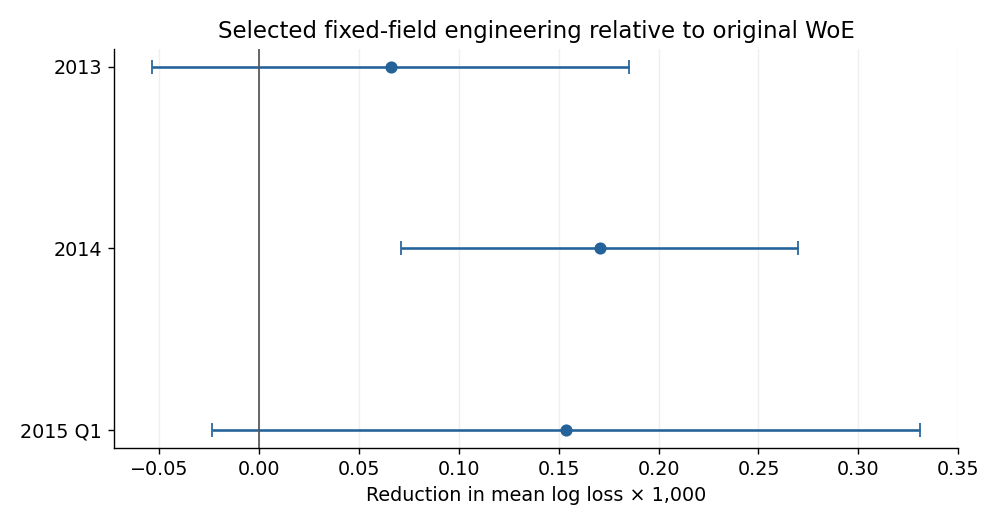

In [5]:
paired = pd.read_csv(folder / "paired_log_loss.csv")
chosen = paired.loc[
    paired.candidate.eq("Both engineered replacements")
    & paired.reference.eq("Published five-variable WoE")
    & paired.scenario.eq("Recorded outcomes") & paired["sample"].eq("All loans")
    & (paired.period.isin(["2013", "2014"]) | paired.calibration.eq("2014 offsets"))
]
assert len(chosen) == 3
figure, axis = plt.subplots(figsize=(8, 4.2))
values = 1000 * chosen.log_loss_reduction.to_numpy()
errors = np.vstack([values - 1000 * chosen.lower_95, 1000 * chosen.upper_95 - values])
axis.errorbar(values, np.arange(len(chosen)), xerr=errors, fmt="o", color="#24639A", capsize=4)
axis.axvline(0, color="#555555", linewidth=1)
axis.set_yticks(np.arange(len(chosen)), chosen.period)
axis.invert_yaxis()
axis.set(xlabel="Reduction in mean log loss × 1,000", title="Selected fixed-field engineering relative to original WoE")
axis.grid(axis="x", alpha=.2)
figure.tight_layout()
plt.show()

## Interpretation and reproducibility

The 2015 Q1 loss reduction is 0.033% and its paired interval spans zero. The two formulas preserve five raw inputs and five point contributions. The primary model is retained.

The runner stages compact-woe and business-woe rebuild the compact studies after their dependencies. The source dictionary, preparation, binning, logistic model and later-outcome calibration inputs are described in the README. Later cohorts have already informed development, so new model changes need a later untouched evaluation period.